In [1]:
import pandas as pd
import numpy as np
import shutil
import seaborn
import torch
import matplotlib.pyplot as plt
import soundfile as sf
from Audio_To_Mel import AudioToMelSpectrogram
import os
from Chunk_Generator import generate_chunks 

In [2]:
# load the AVEHCC data labels table
df = pd.read_csv("./AVEHCC/labels.csv", sep=";", index_col=0)
df.head()

,location,vehicle,timestamp,direction,category,speed,speed_limit
0,1,1,2.168833,left,car,66.2041,50
1,1,2,7.440767,left,car,60.0204,50
2,1,3,12.545867,right,car,83.4048,50
3,1,4,35.435400,left,car,61.1117,50
4,1,5,37.971267,left,car,67.2954,50


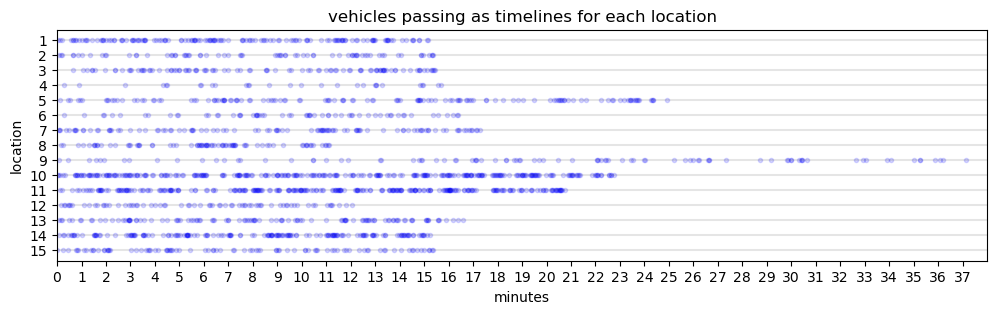

In [7]:
# visualize the recorded traffic data

locations = np.arange(1, 16)

plt.figure(figsize=(12, 3))
for loc in locations:

    x = np.array(df[df.location == loc].timestamp.to_list())/60
    y = [loc]*len(x)

    plt.plot((0, 38), (loc, loc), c="black", alpha=0.1)
    plt.scatter(x, y, marker=".", alpha=0.15, c="blue")

plt.gca().invert_yaxis()
plt.xticks(np.arange(38))
plt.yticks(locations)
plt.xlim(0, 38)
plt.ylabel("location")
plt.xlabel("minutes")
plt.title("vehicles passing as timelines for each location")
plt.show()

In [12]:
# show the length of the recordings as well as the number of vehicles and determin the traffic density

for loc in locations:
    
    # file length in seconds
    file = f"./AVEHCC/location_{loc}/{loc}_gp.wav"
    audio, sr = sf.read(file)

    length = int(len(audio)/sr)
    
    # vehicle count
    count = len(df[df.location == loc])

    # traffic density
    density = count*3600/length
    
    print(f"location {loc:2} -> {length:5} sec. | {count:4} vehicles | {round(density ,1)} per hour")

location  1 ->   912 sec. |  144 vehicles | 568.4 per hour
location  2 ->   923 sec. |   72 vehicles | 280.8 per hour
location  3 ->   928 sec. |   99 vehicles | 384.1 per hour
location  4 ->   944 sec. |   29 vehicles | 110.6 per hour
location  5 ->  1502 sec. |  134 vehicles | 321.2 per hour
location  6 ->  1028 sec. |   61 vehicles | 213.6 per hour
location  7 ->  1149 sec. |  104 vehicles | 325.8 per hour
location  8 ->   676 sec. |   78 vehicles | 415.4 per hour
location  9 ->  2236 sec. |   94 vehicles | 151.3 per hour
location 10 ->  1381 sec. |  295 vehicles | 769.0 per hour
location 11 ->  1248 sec. |  272 vehicles | 784.6 per hour
location 12 ->   726 sec. |   69 vehicles | 342.1 per hour
location 13 ->   999 sec. |  112 vehicles | 403.6 per hour
location 14 ->   921 sec. |  168 vehicles | 656.7 per hour
location 15 ->   925 sec. |   90 vehicles | 350.3 per hour


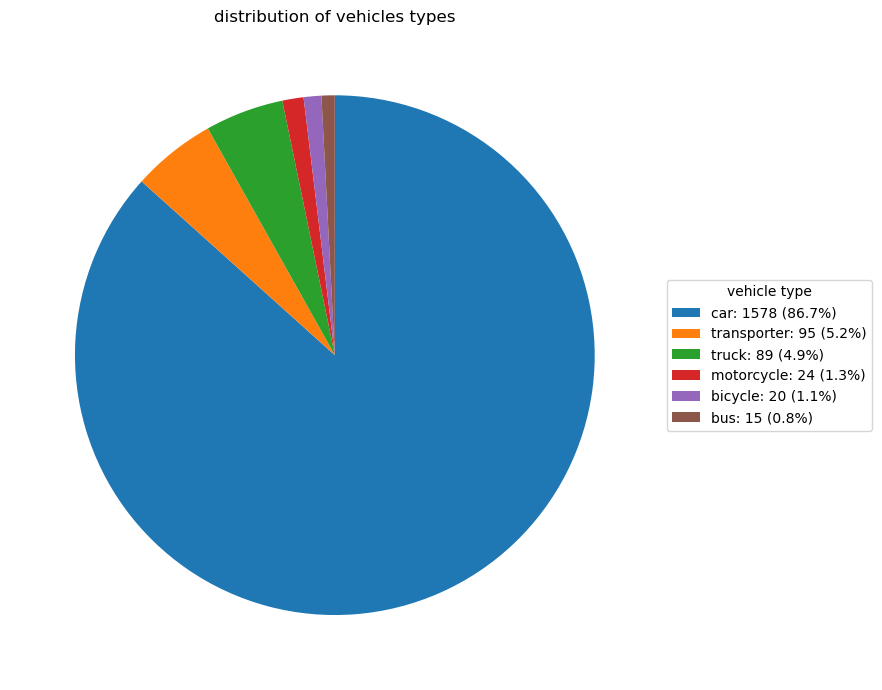

In [14]:
# show the distribution of vehicle types

counts = df[df.location <= 15]["category"].value_counts()
percentages = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(9, 7))

wedges, _ = ax.pie(
    counts,
    startangle=90,
    counterclock=False
)

legend_labels = [
    f"{category}: {count} ({percentage:.1f}%)"
    for category, count, percentage
    in zip(counts.index, counts.values, percentages.values)
]

ax.legend(
    wedges,
    legend_labels,
    title="vehicle type",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    fontsize=10
)

ax.set_title("distribution of vehicles types")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

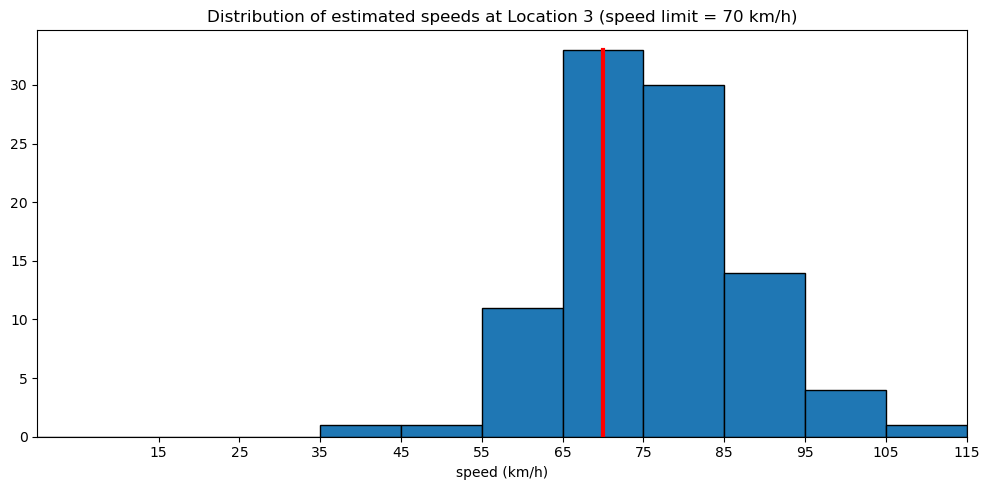

In [26]:
# show the distribution of estimated speeds

location = 3

speed_limit = df[df.location == location].speed_limit.to_list()[0]

bins = [0, 15] + list(range(25, 116, 10))

counts = pd.cut(
    df[df.location == location]["speed"],
    bins=bins,
    right=False
).value_counts(sort=False)

plt.figure(figsize=(10, 5))

widths = np.diff(bins)
centers = (np.array(bins[:-1]) + np.array(bins[1:])) / 2

plt.bar(
    centers,
    counts.values,
    width=widths,
    edgecolor="black",
    align="center"
)

plt.xlabel("speed (km/h)")
plt.title(f"Distribution of estimated speeds at Location {location} (speed limit = {speed_limit} km/h)")

plt.plot((speed_limit, speed_limit), (0, max(counts)), color="red", linewidth=3)

plt.xticks(bins[1:])

plt.xlim(bins[0], bins[-1])
plt.tight_layout()
plt.show()